In [36]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression , Ridge , Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [6]:
df=pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [8]:
df.shape
df.describe()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [10]:
df.isna().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [16]:
#remove missing vals , duplicate values , invalid NYC trip records

columns = ['fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude',
           'dropoff_longitude', 'dropoff_latitude', 'passenger_count']
rides = df[columns].drop_duplicates().copy()
rides['pickup_datetime']=pd.to_datetime(rides['pickup_datetime'],errors='coerce',utc=True)
rides=rides.dropna()
rides=rides[(rides['fare_amount']>0)& rides['passenger_count'].between(1,6)]
for col in ['pickup_longitude','dropoff_longitude']:
    rides=rides[rides[col].between(-75,-72)]

for col in ['pickup_latitude','dropoff_latitude']:
    rides=rides[rides[col].between(40,42)]

print(len(rides))

195100


In [26]:
#calc the distance 
lat1, lon1, lat2, lon2 = np.radians(rides[
    ['pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude']].to_numpy()).T

a=np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
rides['km_dist']=6371*2*np.arcsin(np.sqrt(np.clip(a,0,1)))

rides=rides[rides['km_dist']>0].copy()

rides['hour'] = rides['pickup_datetime'].dt.hour
rides['year'] = rides['pickup_datetime'].dt.year
features = ['km_dist', 'passenger_count', 'hour', 'year']

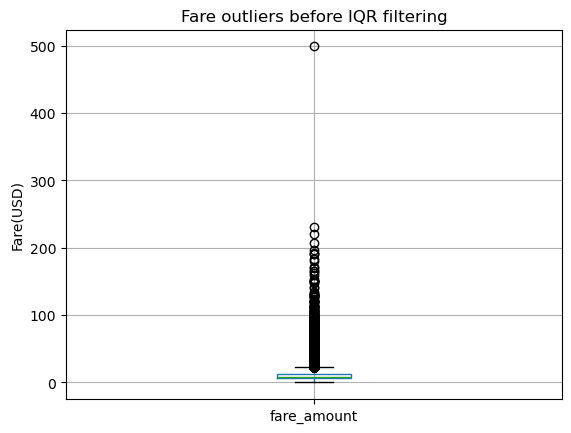

,km_dist,passenger_count,hour,year,fare_amount
km_dist,1.000000,0.007191,-0.029922,0.021812,0.835422
passenger_count,0.007191,1.000000,0.014875,0.005151,0.011839
hour,-0.029922,0.014875,1.000000,0.001924,-0.020650
year,0.021812,0.005151,0.001924,1.000000,0.120449
fare_amount,0.835422,0.011839,-0.020650,0.120449,1.000000


In [28]:
rides.boxplot(column='fare_amount')
plt.title('Fare outliers before IQR filtering')
plt.ylabel('Fare(USD)')
plt.show()
display(rides[features+['fare_amount']].corr())

In [40]:
train , test=train_test_split(rides,test_size=0.2,random_state=42)

for col in ['fare_amount','km_dist']:
    q1=train[col].quantile(0.25)
    q3=train[col].quantile(0.75)

    iqr=q3-q1

    lower=q1-1.5*iqr
    upper=q3+1.5*iqr

    train=train[
        (train[col]>=lower) & 
        (train[col]<=upper)
        ]

X_train=train[features]
y_train=train['fare_amount']

X_test=test[features]
y_test=test['fare_amount']


In [44]:
#models
linear=LinearRegression()
ridge=Ridge(alpha=1)
lasso=Lasso(alpha=0.01)

#scale the data 
scaler=StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

#Linear Regression
linear.fit(X_train_scaled,y_train)

linear_pred=linear.predict(X_test_scaled)

linear_r2=r2_score(y_test,linear_pred)
linear_rmse=np.sqrt(mean_squared_error(y_test,linear_pred))

#Ridge
ridge.fit(X_train_scaled,y_train)

ridge_pred=ridge.predict(X_test_scaled)

ridge_r2=r2_score(y_test,ridge_pred)
ridge_rmse=np.sqrt(mean_squared_error(y_test,ridge_pred))

#Lasso
lasso.fit(X_train_scaled,y_train)

lasso_pred=lasso.predict(X_test_scaled)

lasso_r2=r2_score(y_test,lasso_pred)
lasso_rmse=np.sqrt(mean_squared_error(y_test,lasso_pred))

# Display the results
results = pd.DataFrame({
    'Model': ['Linear', 'Ridge', 'Lasso'],
    'R2': [linear_r2, ridge_r2, lasso_r2],
    'RMSE': [linear_rmse, ridge_rmse, lasso_rmse]
})

display(results)

,Model,R2,RMSE
0,Linear,0.717705,5.145517
1,Ridge,0.717704,5.145525
2,Lasso,0.717265,5.149521
